# Imports

In [6]:
import matplotlib.pyplot as plt
import cv2
from os import listdir
import tifffile as tf
from pathlib import Path
import numpy as np
from cv_skunkworks import (
  gamma_adjustment,
  unique_pixels,
  cluster_image_kmeans,
  normalize_image
)

TARGET_DIRECTORY = 'amyloid-fibrils'
DATA_PATH = Path('data')
FRAME_SEGMENTED_PATH = DATA_PATH / 'frame-segmented'
INPUT_PATH = FRAME_SEGMENTED_PATH / TARGET_DIRECTORY

# Gamma Adjustment

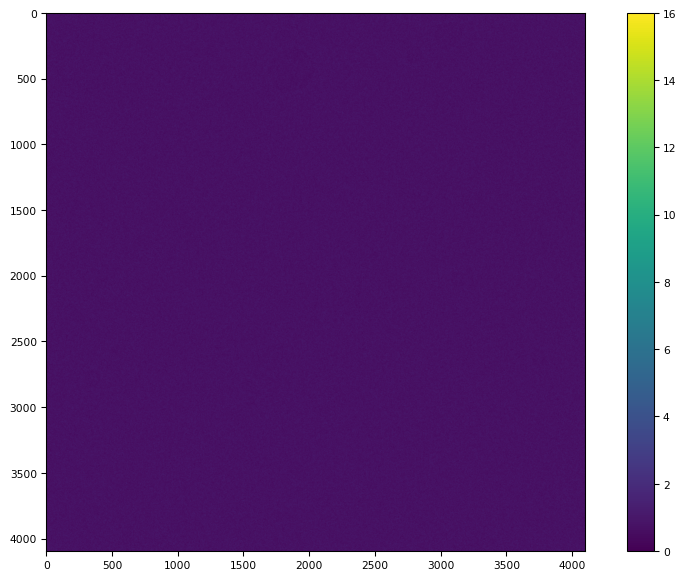

In [ ]:
TIFF_PATH = INPUT_PATH / '0_frame_005.tiff'

im1 = tf.imread(TIFF_PATH)

tf.imshow(im1)
plt.show()

# print(image.shape)
# print(image.dtype)
# print(image.min(), image.max())

# normal_value = image.max()
# gamma_min = 0.01
# gamma_max = 2.0

# def draw_histogram_and_image(axes, image_data, title):
#   axes[0].cla()
#   axes[1].cla()

#   counts, bins = np.histogram(image_data, bins=256)
#   axes[0].stairs(counts, bins)
#   axes[0].set_title(f'{title} histogram')
#   axes[0].set_xlabel('Pixel value')
#   axes[0].set_ylabel('Pixel count')

#   display_image = normalize_image(image_data)*255
#   if display_image.ndim == 3 and display_image.shape[2] == 3:
#     display_image = display_image[..., ::-1]

#   axes[1].imshow(display_image, cmap='gray')
#   axes[1].set_title(title)
#   axes[1].axis('off')

#   axes[0].figure.tight_layout()

# try:
#   from IPython.display import clear_output, display
#   from ipywidgets import FloatSlider, Output, VBox

#   gamma_slider = FloatSlider(
#     value=1.0,
#     min=gamma_min,
#     max=gamma_max,
#     step=0.01,
#     description='Gamma',
#     readout_format='.2f',
#     continuous_update=False,
#   )
#   gamma_output = Output()
#   gamma_fig, gamma_axes = plt.subplots(1, 2, figsize=(12, 4))
#   plt.close(gamma_fig)

#   def plot_gamma_adjustment(change=None):
#     gamma = gamma_slider.value
#     gamma_image = gamma_adjustment(image, gamma, normal_value)
#     draw_histogram_and_image(gamma_axes, gamma_image, f'Gamma {gamma:.2f}')

#     with gamma_output:
#       clear_output(wait=True)
#       display(gamma_fig)

#   gamma_slider.observe(plot_gamma_adjustment, names='value')
#   display(VBox([gamma_slider, gamma_output]))
#   plot_gamma_adjustment()
# except ImportError:
#   print('Install ipywidgets to use the interactive gamma slider.')

# Grayscale

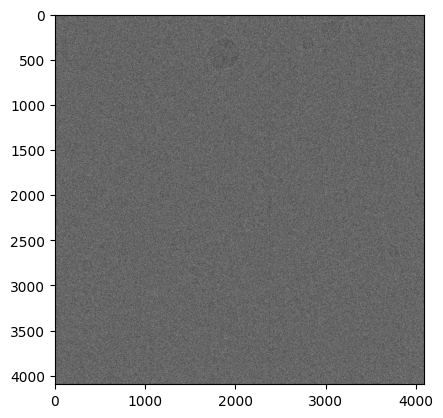

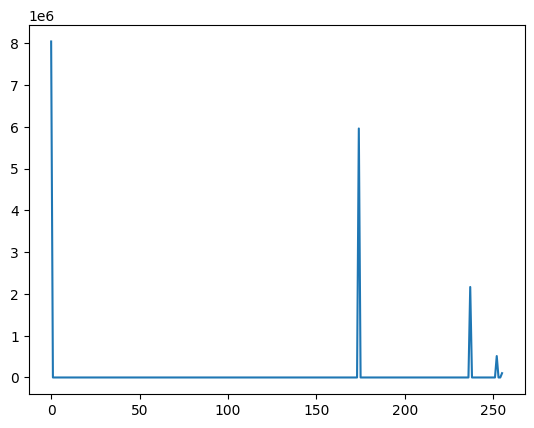

In [3]:
im = cv2.imread(INPUT_PATH / '0_frame_005.tiff', cv2.IMREAD_GRAYSCALE)

im = cv2.equalizeHist(im)

# im = gamma_adjustment(im, 4.0)

plt.imshow(im, cmap='gray')
plt.show()

hist = cv2.calcHist([im], [0], None, [256], [0, 256])
plt.plot(hist)
plt.show()

# Max Filter

# Delete Zero and Redistribute Features

In [4]:
TIFF_PATH = INPUT_PATH / '0_frame_005.tiff'

def read_tiff_preserve_depth(path):
  try:
    return tifffile.imread(path)
  except ValueError as error:
    if 'imagecodecs' not in str(error):
      raise

    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
      raise RuntimeError(f'Could not read TIFF image: {path}') from error
    return image

image = read_tiff_preserve_depth(TIFF_PATH).astype('float32')

print(image.shape)
print(image.dtype)
print(image.min(), image.max())



(4096, 4096)
float32
0.0 10.0
